**Aim:** anlysis of scRNA-seq data

**Tools**: 
1. Preprocessing: [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
2. Normalization/denoising/imputation of expression: [`scvi`](https://docs.scvi-tools.org/en/stable/user_guide/models/scvi.html)

In [37]:
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import scez

In [40]:
from utils import clustering

# 1. Preprocessing

## Run `scVI`

### Prepare data 

In [2]:
results_file = 'preprocessing/adata-cleaned.h5ad.gz'

adata0 = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Exclude female!?

In [22]:
adata0 = adata0[~adata0.obs.cond.str.contains('female')].copy()

___
https://docs.scvi-tools.org/

In [23]:
adata = adata0.copy()

In [24]:
adata

AnnData object with n_obs × n_vars = 21614 × 22288
    obs: 'batch', 'cond', 'group'
    layers: 'counts'

In [25]:
adata.layers["counts"] = adata.X.copy() # preserve counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata # freeze the state in `.raw`

In [26]:
adata

AnnData object with n_obs × n_vars = 21614 × 22288
    obs: 'batch', 'cond', 'group'
    uns: 'log1p'
    layers: 'counts'

https://docs.scvi-tools.org/en/stable/tutorials/notebooks/api_overview.html#Loading-and-preparing-data
> Finally, we perform feature selection, to reduce the number of features (genes in this case) used as input to the scvi-tools model. For best practices of how/when to perform feature selection, please refer to the model-specific tutorial. For scVI, we recommend anywhere from 1,000 to 10,000 HVGs, but it will be context-dependent.


In [28]:
sc.pp.highly_variable_genes(
    adata, #min_mean=0.0125, max_mean=3, min_disp=0.5,
    n_top_genes=10000,
    subset=True,
    layer="counts",
    flavor="cell_ranger",
    batch_key="batch"
)


/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:478: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  hvg = hvg.append(missing_hvg, ignore_index=True)
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:478: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  hvg = hvg.append(missing_hvg, ignore_index=True)
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:478: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  hvg = hvg.append(missing_hvg, ignore_index=True)
/data_gilbert/home/aarab/anaconda3/envs/sc-analys

#### Run `scvi`

In [ ]:
# scvi.model.SCVI.setup_anndata(
#     adata,
#     layer="counts",
#     batch_key="batch",
#     categorical_covariate_keys=["batch", "group"],
#     # continuous_covariate_keys=["percent_mito", "percent_ribo"]
# )


In [ ]:
# model = scvi.model.SCVI(adata)

In [ ]:
# model

In [ ]:
# model.train(max_epochs=400,train_size=0.8,validation_size=0.2)

In [ ]:
# model.save("preprocessing/scvi_model/")

___

Load pre-trained model:

In [29]:
model = scvi.model.SCVI.load(
    "preprocessing/scvi_model_v1/", adata=adata, use_gpu=False
)

INFO     File preprocessing/scvi_model/model.pt already downloaded                           


### Obtaining model outputs


In [30]:
latent = model.get_latent_representation()

It’s often useful to store the outputs of scvi-tools back into the original anndata, as it permits interoperability with Scanpy.


In [31]:
adata.obsm["X_scVI"] = latent

In [32]:
adata.layers["scvi_normalized"] = model.get_normalized_expression(
    library_size=10e4
)

In [33]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', '_scvi_uuid', '_scvi_manager_uuid'
    obsm: '_scvi_extra_categorical_covs', 'X_scVI'
    layers: 'counts', 'scvi_normalized'

In [34]:
results_file = 'preprocessing/adata-denoised.h5ad.gz'

adata.write_h5ad(results_file)

### Plot training epochs ...

In [35]:
model.history.keys()

dict_keys(['train_loss_step', 'train_loss_epoch', 'elbo_train', 'kl_global_train', 'kl_local_train', 'reconstruction_loss_train'])

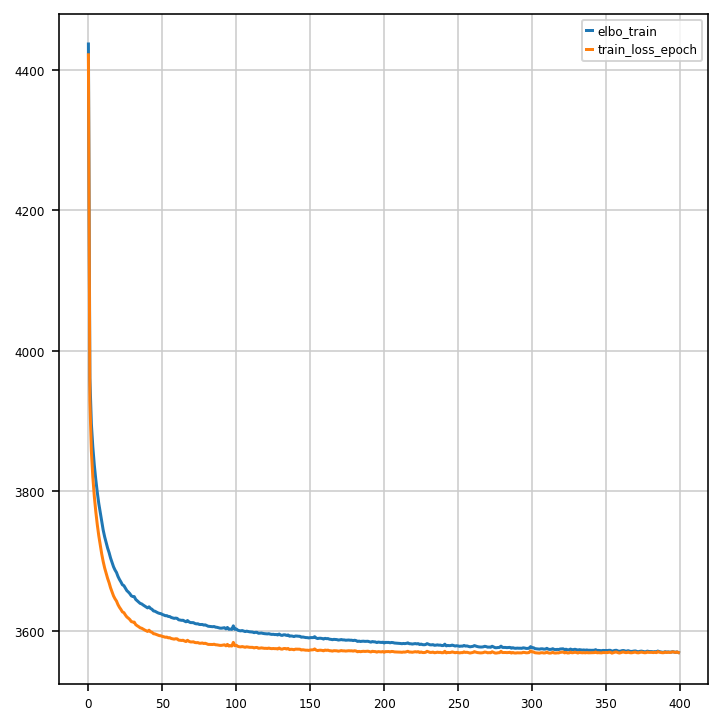

In [38]:
fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(5,5),dpi=72)

ax.plot(model.history["elbo_train"], label="elbo_train")
ax.plot(model.history["train_loss_epoch"], label="train_loss_epoch")
# axes[i].set_ylim(9000, 15000)
ax.legend()

fig.tight_layout()
# fig.savefig('figures/totalVI_training.pdf')

## Explore

In [ ]:
results_file = 'preprocessing/adata-denoised.h5ad.gz'

adata = sc.read_h5ad(results_file)

raw counts

In [ ]:
# # run PCA then generate UMAP plots
# sc.tl.pca(adata)
# sc.pp.neighbors(adata, n_pcs=30, n_neighbors=20)
# sc.tl.umap(adata, min_dist=0.1)

In [ ]:
# sc.pl.umap(
#     adata,
#     color=["batch"],
#     frameon=False,alpha=0.5,size=10
# )

scvi counts

In [49]:
clustering(
    adata,
    rep='X_scVI',
    n_comps = 10,
    n_neighbor = 30,
    res = 0.75,
    key="leiden_scVI"
)

In [ ]:
# # use scVI latent space for UMAP generation
# sc.pp.neighbors(adata, use_rep="X_scVI")
# sc.tl.umap(adata, min_dist=0.3)

In [ ]:
# # neighbors were already computed using scVI
# sc.tl.leiden(adata, key_added="leiden_scVI", resolution=0.75)

### UMAP after denoising 

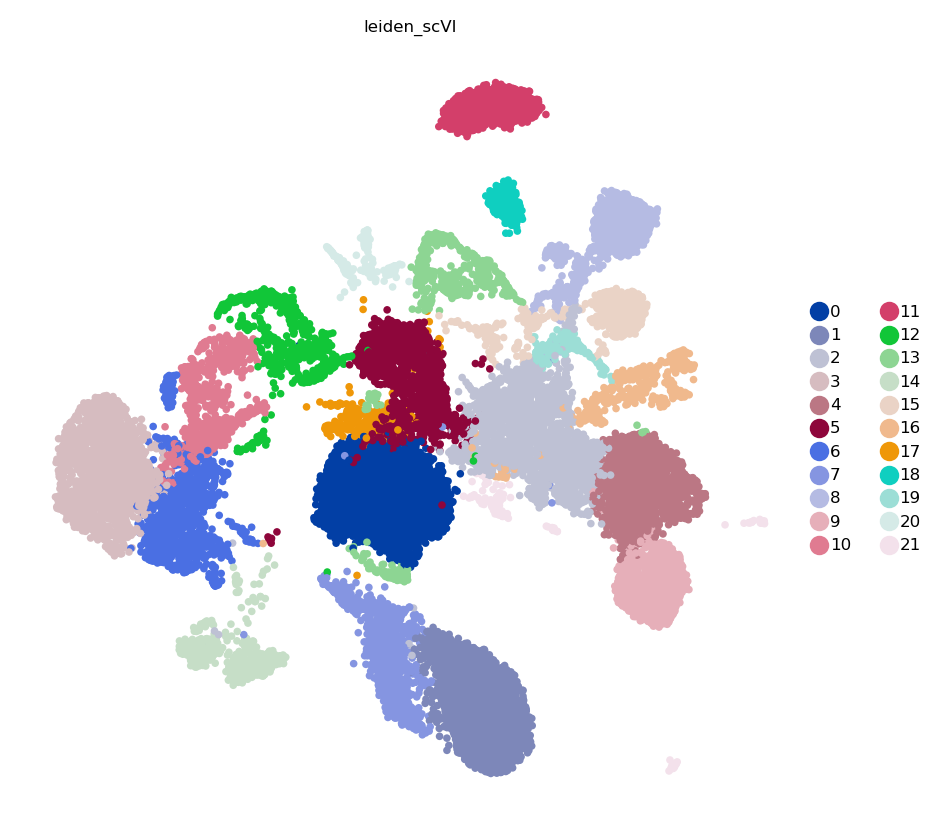

In [50]:
sc.pl.umap(
    adata,
    color=[#'group',"batch",
           'leiden_scVI'],
    frameon=False,alpha=1,size=30,
    # add_outline=0.1
)

# 

In [ ]:
results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'

adata.write_h5ad(results_file)

In [51]:
!date

Tue Nov 22 21:57:30 PST 2022
